# Customer Segmentation with RFM + K-Means

**Goal:** group the customers of an online retailer into segments the marketing team can act on.

**Approach**
1. Clean ~540k raw transactions (UCI *Online Retail*, Dec 2010 – Dec 2011)
2. Engineer **RFM** features per customer: **R**ecency, **F**requency, **M**onetary
3. Transform (log) and standardize, then cluster with **K-Means**
4. Choose **K** with the **elbow** and **silhouette** methods
5. Visualize the clusters with **PCA**
6. Translate each cluster into a **business segment** with a recommended action

All reusable code lives in `src/segmentation/`; this notebook tells the story step by step.
`python main.py` runs the same pipeline end-to-end and writes everything to `reports/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from segmentation import data, rfm as rfm_mod, clustering, interpret, plots
from segmentation.synthetic import make_transactions

pd.set_option("display.float_format", "{:,.2f}".format)
%matplotlib inline

## 1. Load the data

Run `python scripts/download_data.py` once to fetch the dataset into `data/raw/`.

In [2]:
DATA_PATH = ROOT / "data" / "raw" / "Online Retail.xlsx"
DEMO = not DATA_PATH.exists()

if DEMO:
    print("Dataset not found -> using SYNTHETIC demo data. Run scripts/download_data.py for the real thing.")
    raw = make_transactions()
else:
    raw = data.load_raw(DATA_PATH)

print(raw.shape)
raw.head()

Dataset not found -> using SYNTHETIC demo data. Run scripts/download_data.py for the real thing.
(39525, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,542974,23625,ITEM,3,2010-12-02 02:03:00,25.82,"13,634.00",United Kingdom
1,542974,23327,ITEM,9,2010-12-02 02:03:00,7.99,"13,634.00",United Kingdom
2,542974,23499,ITEM,9,2010-12-02 02:03:00,6.96,"13,634.00",United Kingdom
3,542974,23593,ITEM,7,2010-12-02 02:03:00,9.79,"13,634.00",United Kingdom
4,542974,23634,ITEM,5,2010-12-02 02:03:00,8.46,"13,634.00",United Kingdom


In [3]:
raw.info()
raw.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39525 entries, 0 to 39524
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    39525 non-null  object        
 1   StockCode    39525 non-null  object        
 2   Description  39525 non-null  object        
 3   Quantity     39525 non-null  int64         
 4   InvoiceDate  39525 non-null  datetime64[ns]
 5   UnitPrice    39525 non-null  float64       
 6   CustomerID   37544 non-null  float64       
 7   Country      39525 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 2.4+ MB


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"39,525.00",39525,"39,525.00","37,544.00"
mean,6.74,2011-07-22 00:03:23.884629760,15.35,"13,090.25"
min,-16.00,2010-12-02 02:03:00,0.00,"12,346.00"
25%,5.00,2011-05-16 11:56:00,6.20,"12,710.00"
50%,7.00,2011-08-12 08:18:00,10.55,"13,088.00"
75%,9.00,2011-10-14 11:25:00,18.48,"13,468.00"
max,19.00,2011-12-09 12:00:00,412.99,"13,845.00"
std,3.11,NaN,16.79,434.80


## 2. Clean

Things in the raw file that would distort customer-level metrics:

| Issue | Why it matters | Fix |
|---|---|---|
| Missing `CustomerID` (~25% of rows) | can't attribute to a customer | drop |
| Invoices starting with `C` | cancellations, negative quantities | drop |
| `Quantity <= 0` or `UnitPrice <= 0` | returns, adjustments, free samples | drop |
| Exact duplicate rows | double-counted revenue | drop |

In [4]:
tx, report = data.clean(raw)
pd.Series(report, name="rows").to_frame()

,rows
raw_rows,39525
after_drop_missing_customer,37544
after_drop_cancellations,36821
after_positive_qty_price,36644
after_drop_duplicates,36282
customers,1499


## 3. Exploratory data analysis

Period: 2010-12-02 -> 2011-12-09
Customers: 1,499 | Invoices: 7,695 | Revenue: 3,388,444


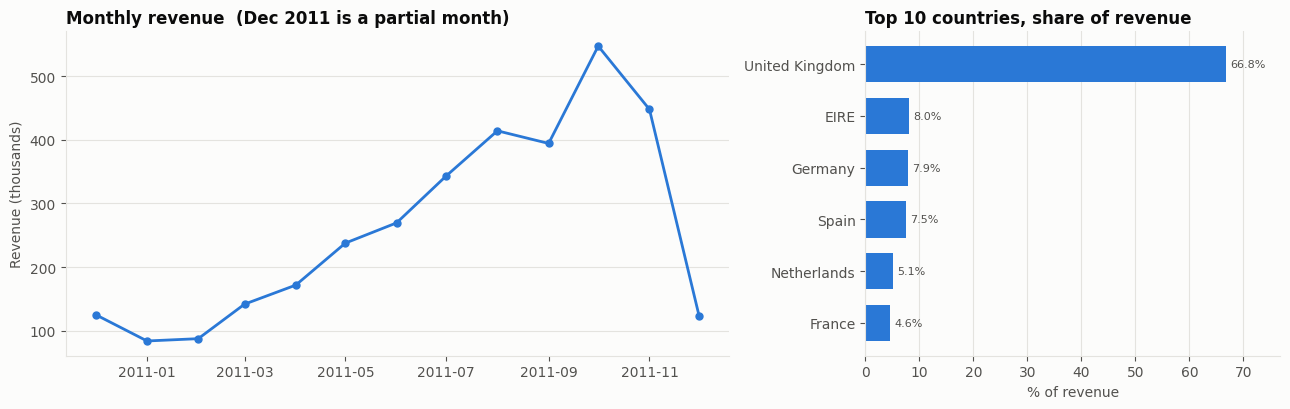

In [5]:
print(f"Period: {tx.InvoiceDate.min():%Y-%m-%d} -> {tx.InvoiceDate.max():%Y-%m-%d}")
print(f"Customers: {tx.CustomerID.nunique():,} | Invoices: {tx.InvoiceNo.nunique():,} | Revenue: {tx.Revenue.sum():,.0f}")
plots.plot_eda_overview(tx)

## 4. RFM features

For each customer, relative to a snapshot date one day after the last transaction:

- **Recency** – days since last purchase (lower = better)
- **Frequency** – number of distinct invoices
- **Monetary** – total revenue

In [6]:
rfm = rfm_mod.compute_rfm(tx)
rfm.describe()

,Recency,Frequency,Monetary
count,"1,499.00","1,499.00","1,499.00"
mean,96.78,5.13,"2,260.47"
std,114.08,5.54,"3,695.11"
min,1.00,1.00,42.16
25%,15.00,2.00,423.67
50%,44.00,3.00,841.56
75%,139.00,6.00,"2,354.15"
max,373.00,33.00,"22,730.59"


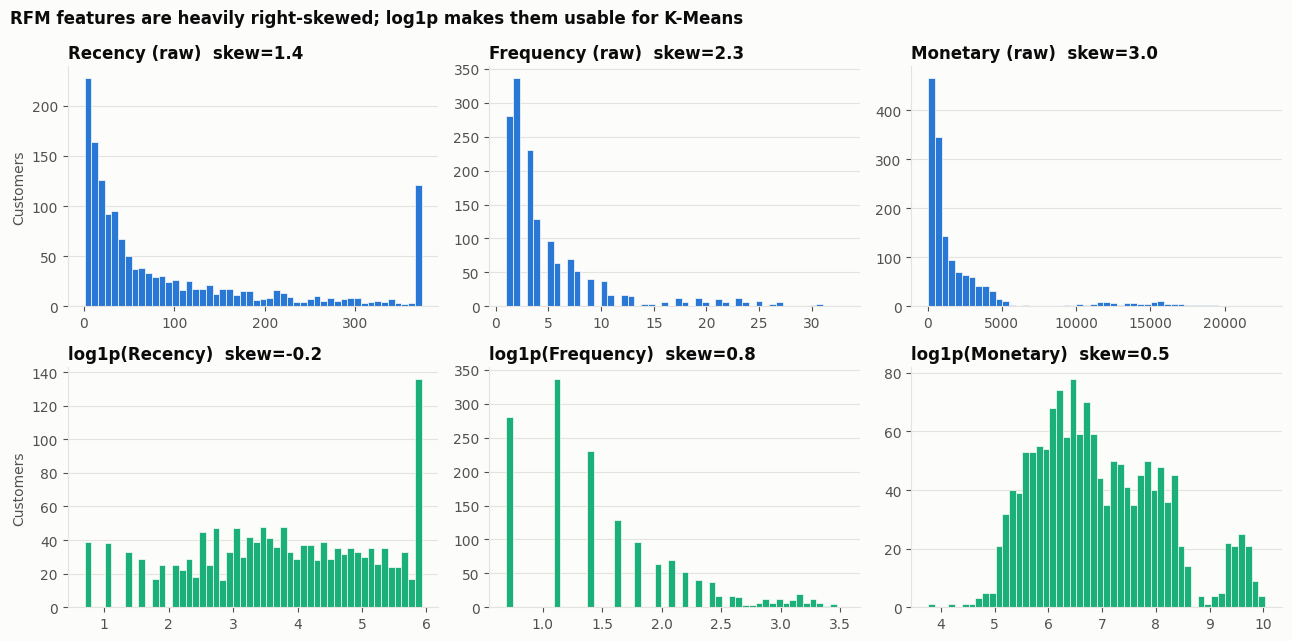

In [7]:
plots.plot_rfm_distributions(rfm);

All three features are strongly **right-skewed**. K-Means minimizes Euclidean distance, so:

1. `log1p` compresses the long tail so a handful of wholesalers don't each become their own cluster
2. `StandardScaler` puts the features on the same scale (otherwise Monetary would dominate)

In [8]:
X, scaler = rfm_mod.scale_rfm(rfm)
pd.DataFrame(X, columns=rfm_mod.RFM_COLS).describe().loc[["mean", "std"]].round(3)

,Recency,Frequency,Monetary
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00


## 5. Choosing K – elbow and silhouette

- **Elbow:** inertia always falls as K grows; we look for the K after which extra clusters stop buying much.
- **Silhouette:** how much closer each customer is to its own cluster than to the next one (−1…1, higher is better).

Silhouette on RFM data usually peaks at K=2 ("good" vs "bad" customers), which isn't useful for marketing.
So we look at K in 3–8 and pick the K closest to the elbow whose silhouette is within 90% of the best in that range.

In [9]:
scores = clustering.evaluate_k(X, range(2, 11))
elbow_k = clustering.find_elbow(scores.index, scores["inertia"])
K, reason = clustering.choose_k(scores)
print(reason)
scores.round(3)

elbow at k=5; best silhouette in [3,8] is 0.389 at k=3; k=5 has silhouette 0.382 and is the closest to the elbow among k values within 90% of the best silhouette.


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"2,154.16",0.46,0.84,"1,628.12"
3,"1,519.17",0.39,0.93,"1,466.22"
4,"1,137.48",0.39,0.86,"1,471.84"
5,870.81,0.38,0.82,"1,555.34"
6,743.79,0.37,0.86,"1,506.74"
7,642.97,0.37,0.89,"1,490.54"
8,559.45,0.36,0.86,"1,499.34"
9,492.26,0.37,0.87,"1,515.22"
10,444.69,0.37,0.85,"1,507.66"


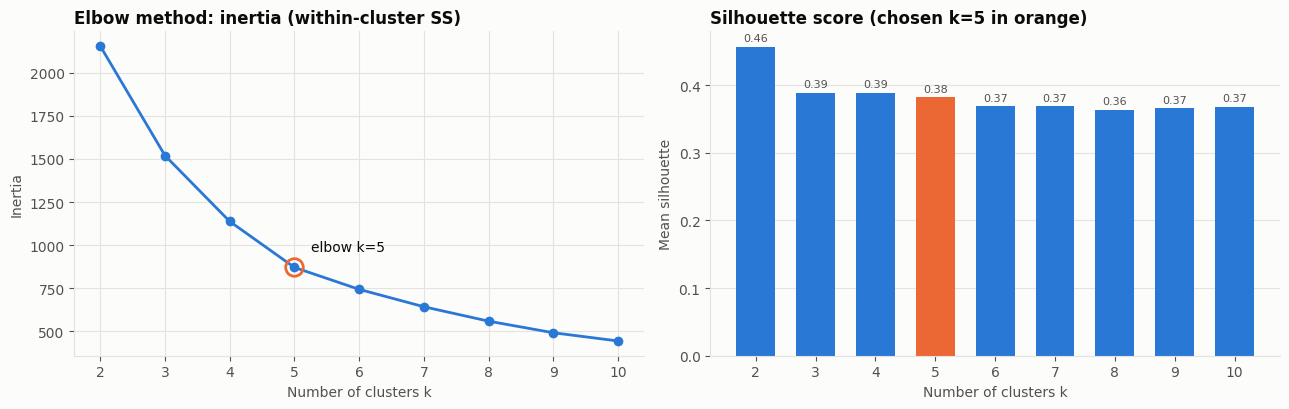

In [10]:
plots.plot_k_selection(scores, K, elbow_k)

In [11]:
km = clustering.fit_kmeans(X, K)
names = interpret.name_clusters(km.cluster_centers_)

seg = rfm.copy()
seg["Cluster"] = km.labels_
seg["Segment"] = seg["Cluster"].map(names)
seg = seg.join(rfm_mod.rfm_scores(rfm))
seg.head()

,Recency,Frequency,Monetary,Cluster,Segment,R_score,F_score,M_score,RFM_score
CustomerID,,,,,,,,,
12346,123,1,431.54,0,Hibernating / Lost,2,1,2,5
12347,36,16,"6,780.45",2,Champions,3,5,5,13
12348,85,1,334.29,0,Hibernating / Lost,2,1,1,4
12349,19,22,"16,723.99",2,Champions,4,5,5,14
12350,9,7,"1,929.47",1,Loyal Customers,5,4,4,13


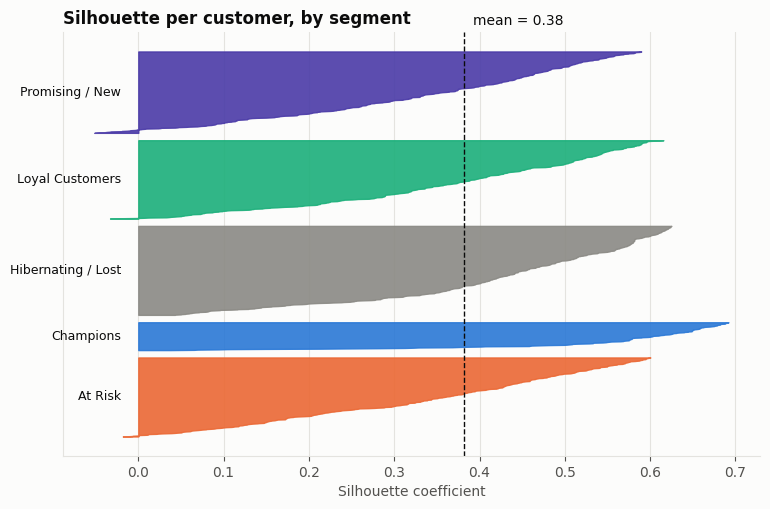

In [12]:
plots.plot_silhouette_detail(X, km.labels_, names)

## 6. Visualizing the clusters with PCA

PCA projects the 3 scaled RFM features onto 2 axes that keep as much variance as possible.
The loadings below show what each axis means.

Explained variance: [75.1 24.2] %


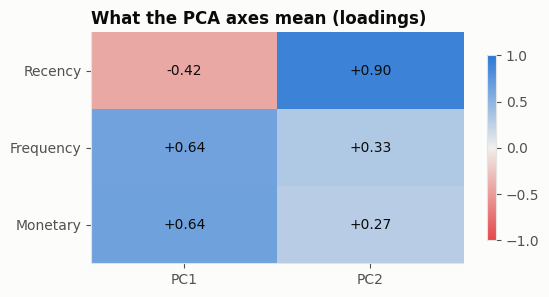

In [13]:
X2, pca = clustering.pca_project(X)
print("Explained variance:", (pca.explained_variance_ratio_ * 100).round(1), "%")
plots.plot_pca_loadings(pca);

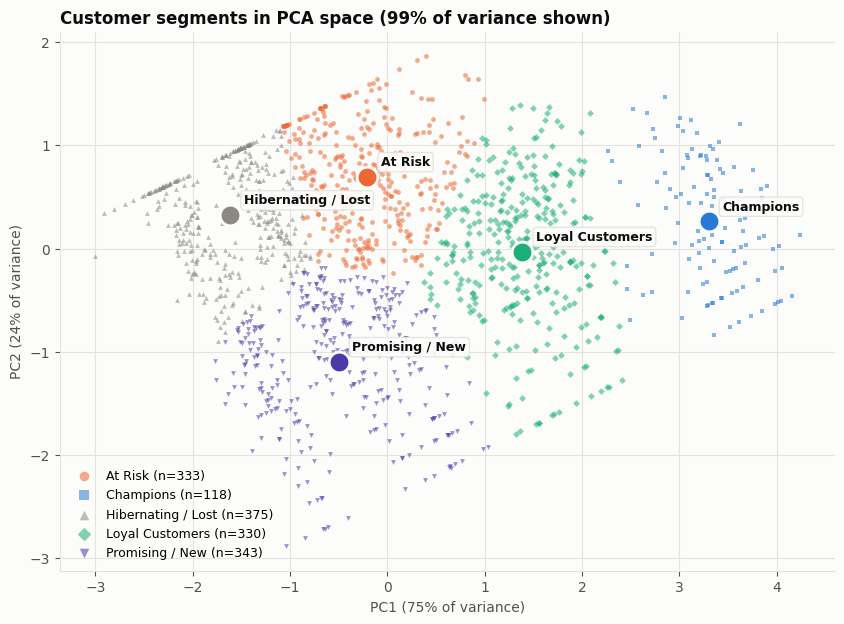

In [14]:
plots.plot_pca_segments(X2, seg["Segment"], pca, pca.transform(km.cluster_centers_), names)

Interactive versions (requires `plotly`): hover a point to see the customer's RFM values.

In [15]:
try:
    import plotly.express as px
    df = seg.reset_index().assign(PC1=X2[:, 0], PC2=X2[:, 1])
    fig = px.scatter_3d(df, x="Recency", y="Frequency", z="Monetary", color="Segment",
                        color_discrete_map={s: plots.segment_color(s) for s in df.Segment.unique()},
                        log_y=True, log_z=True, opacity=0.7, hover_data=["CustomerID"])
    fig.update_traces(marker=dict(size=3))
    fig.show()
except ImportError:
    print("plotly not installed: pip install plotly")

## 7. Segment profiles

The heatmap shows each centroid in standard deviations from the average customer
(Recency flipped so **blue = better than average** everywhere).

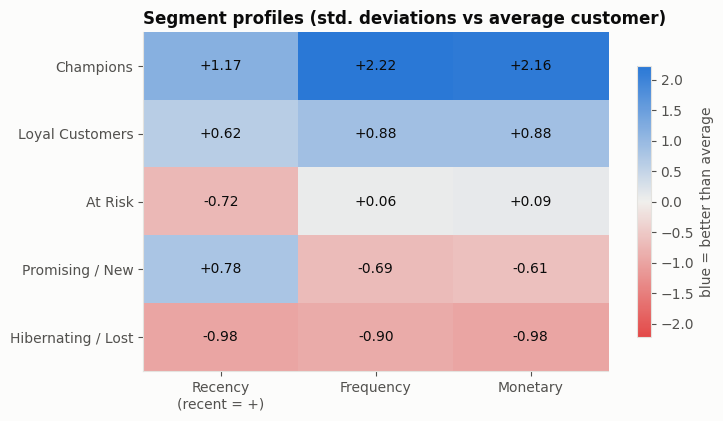

In [16]:
plots.plot_segment_heatmap(km.cluster_centers_, names);

In [17]:
profile = interpret.segment_profile(seg)
profile[["Customers", "Customer_share_%", "Revenue_share_%",
         "Recency_median_days", "Frequency_median", "Monetary_median"]]

,Customers,Customer_share_%,Revenue_share_%,Recency_median_days,Frequency_median,Monetary_median
Segment,,,,,,
Champions,118,7.87,48.00,7.00,21.00,"13,789.61"
Loyal Customers,330,22.01,30.11,19.50,8.00,"3,012.62"
At Risk,333,22.21,12.28,117.00,4.00,"1,125.40"
Promising / New,343,22.88,5.74,16.00,2.00,544.93
Hibernating / Lost,375,25.02,3.88,181.00,2.00,338.47


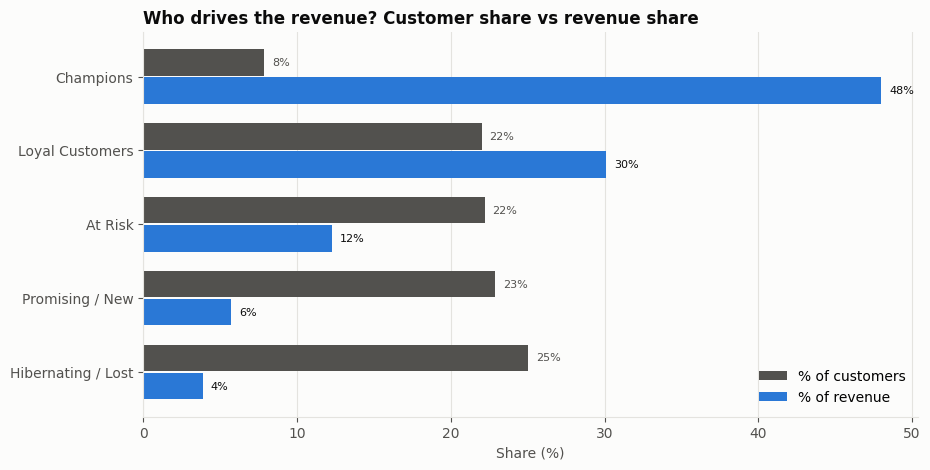

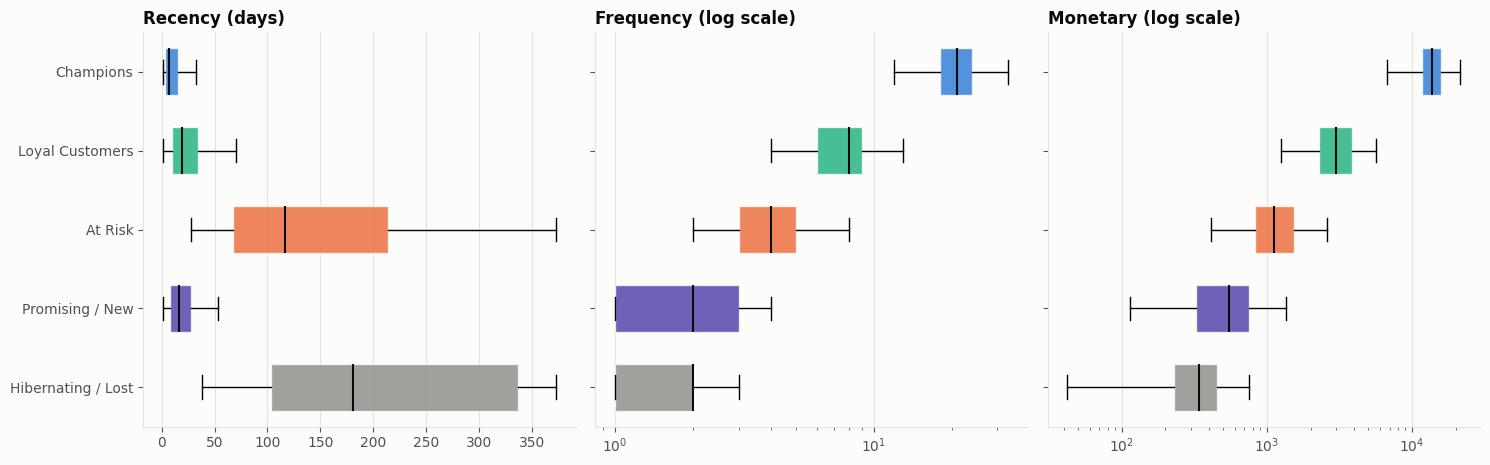

In [18]:
plots.plot_segment_share(profile)
plots.plot_segment_boxplots(seg)

### Sanity check against classic RFM scores

Quintile RFM scores (1–5 per dimension) are the rule-based baseline marketers know.
The K-Means segments should order the same way on average.

In [19]:
seg.groupby("Segment")[["R_score", "F_score", "M_score", "RFM_score"]].mean().sort_values("RFM_score", ascending=False).round(2)

,R_score,F_score,M_score,RFM_score
Segment,,,,
Champions,4.55,5.00,5.00,14.55
Loyal Customers,3.93,4.51,4.54,12.98
At Risk,1.94,3.43,3.38,8.75
Promising / New,4.14,2.00,2.10,8.24
Hibernating / Lost,1.59,1.57,1.50,4.66


## 8. Business interpretation & actions

In [20]:
for name, r in profile.iterrows():
    print(f"■ {name}: {int(r.Customers):,} customers ({r['Customer_share_%']:.0f}%) -> {r['Revenue_share_%']:.0f}% of revenue")
    print(f"   typical: last order {r.Recency_median_days:.0f} days ago, {r.Frequency_median:.0f} orders, {r.Monetary_median:,.0f} spent")
    print(f"   who:    {r.Description}")
    print(f"   action: {r.Recommended_action}\n")

■ Champions: 118 customers (8%) -> 48% of revenue
   typical: last order 7 days ago, 21 orders, 13,790 spent
   who:    Bought recently, buy often and spend the most.
   action: Reward them: VIP/loyalty perks, early access to new products, ask for reviews and referrals.

■ Loyal Customers: 330 customers (22%) -> 30% of revenue
   typical: last order 20 days ago, 8 orders, 3,013 spent
   who:    Regular buyers with above-average spend who are still active.
   action: Upsell higher-value products, cross-sell bundles, invite into the loyalty program.

■ At Risk: 333 customers (22%) -> 12% of revenue
   typical: last order 117 days ago, 4 orders, 1,125 spent
   who:    Used to buy often and spend well, but haven't purchased in a while.
   action: Win-back campaign now: personalised emails, limited-time offer, ask what changed.

■ Promising / New: 343 customers (23%) -> 6% of revenue
   typical: last order 16 days ago, 2 orders, 545 spent
   who:    Bought recently but only a few times and 